In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, mean_squared_error,
                             mean_absolute_error, log_loss)

np.random.seed(42)
df = pd.read_csv("data/matches.csv")
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (1243, 31)


,event_name,season,match_number,date,city,venue,team1,team2,toss_winner,toss_decision,...,umpire2,tv_umpire,reserve_umpire,match_type,overs_limit,balls_per_over,gender,team_type,team1_players,team2_players
0,Indian Premier League,2007/08,1.0,18-04-2008,Bangalore,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,...,RE Koertzen,AM Saheba,VN Kulkarni,T20,20,6,male,club,"R Dravid, W Jaffer, V Kohli, JH Kallis, CL Whi...","SC Ganguly, BB McCullum, RT Ponting, DJ Hussey..."
1,Indian Premier League,2007/08,2.0,19-04-2008,Chandigarh,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,bat,...,SL Shastri,RB Tiffin,MSS Ranawat,T20,20,6,male,club,"K Goel, JR Hopes, KC Sangakkara, Yuvraj Singh,...","PA Patel, ML Hayden, MEK Hussey, MS Dhoni, SK ..."
2,Indian Premier League,2007/08,3.0,19-04-2008,Delhi,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,bat,...,GA Pratapkumar,IL Howell,Unknown,T20,20,6,male,club,"G Gambhir, V Sehwag, S Dhawan, MK Tiwary, KD K...","T Kohli, YK Pathan, SR Watson, M Kaif, DS Lehm..."
3,Indian Premier League,2007/08,4.0,20-04-2008,Kolkata,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,...,K Hariharan,Asad Rauf,F Gomes,T20,20,6,male,club,"WP Saha, BB McCullum, RT Ponting, SC Ganguly, ...","AC Gilchrist, Y Venugopal Rao, VVS Laxman, A S..."
4,Indian Premier League,2007/08,5.0,20-04-2008,Mumbai,Wankhede Stadium,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,...,DJ Harper,AV Jayaprakash,SN Bandekar,T20,20,6,male,club,"L Ronchi, ST Jayasuriya, DJ Thornely, RV Uthap...","S Chanderpaul, R Dravid, LRPL Taylor, JH Kalli..."


In [20]:
print("Dataset dimensions:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and missing-value overview:")
df.info()

print("\nSummary of numeric columns:")
display(df.describe())

Dataset dimensions: (1218, 37)

Column names:
['event_name', 'season', 'match_number', 'date', 'city', 'venue', 'team1', 'team2', 'toss_winner', 'toss_decision', 'team1_runs', 'team1_wickets', 'team2_runs', 'team2_wickets', 'winner', 'result_type', 'win_by_runs', 'win_by_wickets', 'player_of_match', 'match_referee', 'umpire1', 'umpire2', 'tv_umpire', 'reserve_umpire', 'match_type', 'overs_limit', 'balls_per_over', 'gender', 'team_type', 'team1_players', 'team2_players', 'bat_first', 'chase', 'target_runs', 'target_wkts', 'runs_vs_avg', 'bat_first_won']

Data types and missing-value overview:
<class 'pandas.DataFrame'>
RangeIndex: 1218 entries, 0 to 1217
Data columns (total 37 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   event_name       1218 non-null   str           
 1   season           1218 non-null   str           
 2   match_number     1144 non-null   float64       
 3   date             1218 non-null   da

,match_number,date,team1_runs,team1_wickets,team2_runs,team2_wickets,win_by_runs,win_by_wickets,overs_limit,balls_per_over,target_runs,target_wkts,runs_vs_avg,bat_first_won
count,1144.000000,1218,1218.000000,1218.000000,1218.000000,1218.000000,1218.000000,1218.000000,1218.0,1218.0,1218.000000,1218.000000,1218.000000,1218.000000
mean,31.941434,2017-07-25 20:28:22.463054,166.224138,5.954844,158.112479,5.885878,14.218391,3.344007,20.0,6.0,168.974548,6.140394,0.908609,0.453202
min,1.000000,2008-04-18 00:00:00,58.000000,0.000000,44.000000,0.000000,0.000000,0.000000,20.0,6.0,67.000000,0.000000,-123.883333,0.000000
25%,16.000000,2012-05-14 00:00:00,144.000000,4.000000,138.000000,4.000000,0.000000,0.000000,20.0,6.0,148.000000,5.000000,-18.895833,0.000000
50%,31.500000,2017-05-05 12:00:00,165.000000,6.000000,160.000000,6.000000,0.000000,3.000000,20.0,6.0,168.000000,6.000000,1.808333,0.000000
75%,47.000000,2022-05-08 18:00:00,188.750000,8.000000,179.000000,8.000000,20.000000,6.000000,20.0,6.0,190.000000,8.000000,22.012500,1.000000
max,72.000000,2026-05-31 00:00:00,287.000000,10.000000,265.000000,10.000000,146.000000,10.000000,20.0,6.0,287.000000,10.000000,107.966667,1.000000
std,18.634042,NaN,34.885513,2.301533,32.574213,2.615160,24.020840,3.359195,0.0,0.0,33.689556,2.130306,31.747817,0.498010


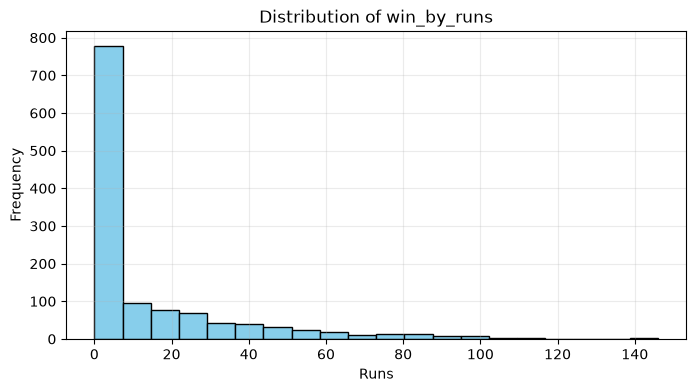

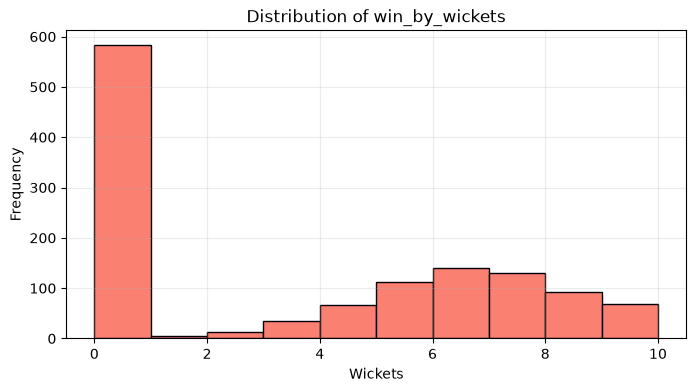

In [5]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()

column_to_plot_1 = "win_by_runs"

plt.figure(figsize=(8, 4))
plt.hist(df[column_to_plot_1].dropna(), bins=20, edgecolor="black", color="skyblue")
plt.title(f"Distribution of {column_to_plot_1}")
plt.xlabel("Runs")
plt.ylabel("Frequency")
plt.grid(alpha=0.25)
plt.show()

column_to_plot_2 = "win_by_wickets"

plt.figure(figsize=(8, 4))
plt.hist(df[column_to_plot_2].dropna(), bins=10, edgecolor="black", color="salmon")
plt.title(f"Distribution of {column_to_plot_2}")
plt.xlabel("Wickets")
plt.ylabel("Frequency")
plt.grid(alpha=0.25)
plt.show()

In [23]:
f = df.replace({"Delhi Daredevils": "Delhi Capitals", "Kings XI Punjab": "Punjab Kings",
                 "Royal Challengers Bangalore": "Royal Challengers Bengaluru",
                 "Rising Pune Supergiants": "Rising Pune Supergiant"})

df = df[(df["winner"] == df["team1"]) | (df["winner"] == df["team2"])].copy()
df["date"] = pd.to_datetime(df["date"], dayfirst=True)
df = df.sort_values("date").reset_index(drop=True)
df["venue"] = df["venue"].str.split(",").str[0]          # "Wankhede Stadium, Mumbai" -> "Wankhede Stadium"
print("Matches after cleaning:", len(df))


other_team = np.where(df["toss_winner"] == df["team1"], df["team2"], df["team1"])
df["bat_first"] = np.where(df["toss_decision"] == "bat", df["toss_winner"], other_team)
df["chase"] = np.where(df["bat_first"] == df["team1"], df["team2"], df["team1"])

bat_first_is_team1 = df["bat_first"] == df["team1"]
df["target_runs"] = np.where(bat_first_is_team1, df["team1_runs"], df["team2_runs"])
df["target_wkts"] = np.where(bat_first_is_team1, df["team1_wickets"], df["team2_wickets"])

# 4. Feature: runs compared with the average of the previous 60 matches (shift(1) = only past matches)
avg_before = df["target_runs"].shift(1).rolling(60, min_periods=10).mean().fillna(160)
df["runs_vs_avg"] = df["target_runs"] - avg_before

# Target: 1 if the team batting first won
df["bat_first_won"] = (df["winner"] == df["bat_first"]).astype(int)

# The numeric feature columns (used for correlation, normalization and the model)
numeric = ["target_runs", "target_wkts", "runs_vs_avg"]
df[["date", "bat_first", "chase", "target_runs", "target_wkts", "runs_vs_avg", "bat_first_won"]].head()

Matches after cleaning: 1218


,date,bat_first,chase,target_runs,target_wkts,runs_vs_avg,bat_first_won
0,2008-04-18,Kolkata Knight Riders,Royal Challengers Bengaluru,222,3,62.0,1
1,2008-04-19,Chennai Super Kings,Punjab Kings,240,5,80.0,1
2,2008-04-19,Rajasthan Royals,Delhi Capitals,129,8,-31.0,0
3,2008-04-20,Deccan Chargers,Kolkata Knight Riders,110,10,-50.0,0
4,2008-04-20,Mumbai Indians,Royal Challengers Bengaluru,165,7,5.0,0


In [21]:
numeric = ["target_runs", "target_wkts", "runs_vs_avg"]
X = pd.get_dummies(df[numeric + ["bat_first", "chase", "venue"]], columns=["bat_first", "chase", "venue"], dtype=int)
y = df["bat_first_won"]

split = int(len(df) * 0.8)
X_train, X_test = X.iloc[:split].copy(), X.iloc[split:].copy()
y_train, y_test = y.iloc[:split], y.iloc[split:]
print("Training matches:", len(X_train), "| Testing matches:", len(X_test))
print("Number of features:", X.shape[1])

Training matches: 974 | Testing matches: 244
Number of features: 75


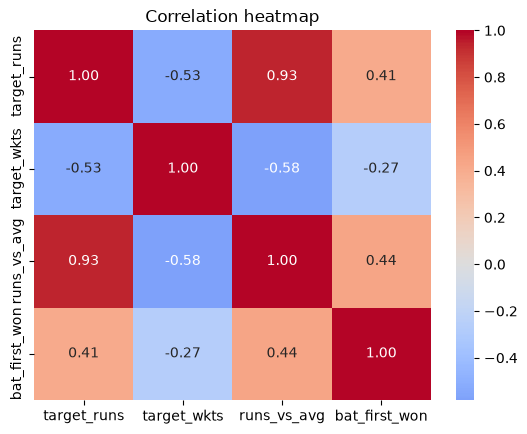

In [22]:
sns.heatmap(df[numeric + ["bat_first_won"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

In [28]:
scaler = StandardScaler()
X_train[numeric] = scaler.fit_transform(X_train[numeric])
X_test[numeric] = scaler.transform(X_test[numeric])

# Remove columns that never appear in the training matches (e.g. grounds used only later)
X_train = X_train.loc[:, X_train.std() > 0]
X_test = X_test[X_train.columns]

# Feature selection: keep the 15 best features
selector = SelectKBest(f_classif, k=15).fit(X_train, y_train)
selected = X_train.columns[selector.get_support()]
X_train, X_test = X_train[selected], X_test[selected]

print("Selected features:", list(selected))

Selected features: ['target_runs', 'target_wkts', 'runs_vs_avg', 'bat_first_Chennai Super Kings', 'bat_first_Gujarat Lions', 'bat_first_Lucknow Super Giants', 'bat_first_Mumbai Indians', 'chase_Chennai Super Kings', 'chase_Deccan Chargers', 'chase_Gujarat Lions', 'chase_Gujarat Titans', 'chase_Pune Warriors', 'venue_Green Park', 'venue_Holkar Cricket Stadium', 'venue_MA Chidambaram Stadium']


In [29]:
numeric = ["target_runs", "target_wkts", "runs_vs_avg"]
X = pd.get_dummies(df[numeric + ["bat_first", "chase", "venue"]], columns=["bat_first", "chase", "venue"], dtype=int)
y = df["bat_first_won"]

split = int(len(df) * 0.8)
X_train, X_test = X.iloc[:split].copy(), X.iloc[split:].copy()
y_train, y_test = y.iloc[:split], y.iloc[split:]
print("Training matches:", len(X_train), "| Testing matches:", len(X_test))
print("Number of features:", X.shape[1])

Training matches: 974 | Testing matches: 244
Number of features: 75


In [30]:
def train_model(X_tr, y_tr):
    """Train a Logistic Regression model (C=0.1 keeps the model simple)."""
    model = LogisticRegression(C=0.1, max_iter=1000)       # C=0.1: stronger regularization to avoid overfitting
    model.fit(X_tr, y_tr)
    return model

def test_model(model, X_te, y_te):
    """Predict on test data and calculate all the metrics."""
    pred = model.predict(X_te)                      # predicted class (0 or 1)
    prob = model.predict_proba(X_te)[:, 1]          # predicted probability that the batting team wins
    return {"pred": pred,
            "Accuracy": accuracy_score(y_te, pred),
            "Precision": precision_score(y_te, pred),
            "Recall": recall_score(y_te, pred),
            "F1": f1_score(y_te, pred),
            "MSE": mean_squared_error(y_te, prob),
            "MAE": mean_absolute_error(y_te, prob),
            "RMSE": np.sqrt(mean_squared_error(y_te, prob))}

model = train_model(X_train, y_train)
res = test_model(model, X_test, y_test)
print("Model trained. Test accuracy:", round(res["Accuracy"], 3))

Model trained. Test accuracy: 0.697
